In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [3]:
file_path = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset dimensions:
(7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

print("Duplicate rows:", df.duplicated().sum())

,Missing Values,Missing Percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


Duplicate rows: 0


Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

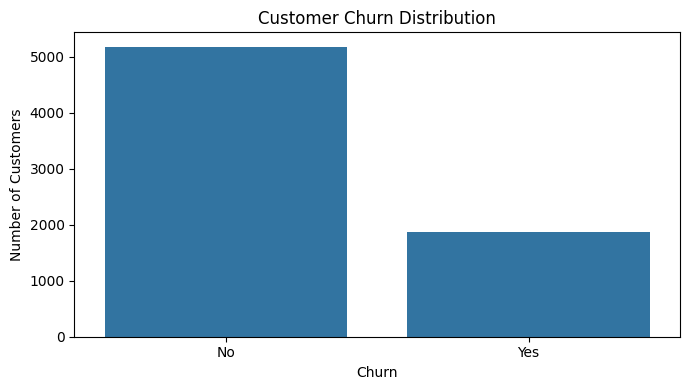

In [6]:
print("Churn counts:")
display(df["Churn"].value_counts(dropna=False))

print("\nChurn percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


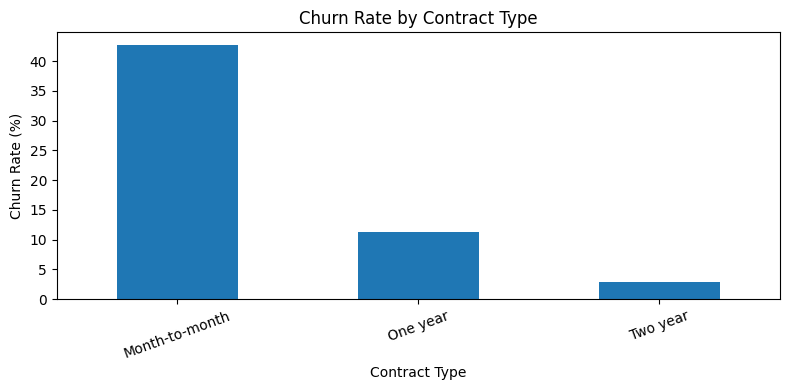

In [7]:
if "Contract" in df.columns and "Churn" in df.columns:
    churn_rate = (
        df.assign(
            Churn_Flag=(
                df["Churn"].astype(str).str.strip().str.lower()
                .eq("yes").astype(int)
            )
        )
        .groupby("Contract")["Churn_Flag"]
        .mean()
        .mul(100)
        .round(2)
    )

    display(churn_rate.rename("Churn Rate (%)").to_frame())

    churn_rate.plot(kind="bar", figsize=(8, 4))
    plt.title("Churn Rate by Contract Type")
    plt.ylabel("Churn Rate (%)")
    plt.xlabel("Contract Type")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("Check whether the columns Contract and Churn exist.")

In [8]:
# Step 2: Prepare data for machine learning

import pandas as pd
from sklearn.model_selection import train_test_split

# Check the column names
print("Dataset columns:")
print(df.columns.tolist())

# Check the target column
print("\nPossible churn columns:")
print([col for col in df.columns if "churn" in col.lower()])

Dataset columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Possible churn columns:
['Churn']


In [9]:
# Step 3: Prepare training and testing data

import pandas as pd
from sklearn.model_selection import train_test_split

# Make a copy of the dataset
data = df.copy()

# Remove customer ID because it does not help predict churn
data = data.drop(columns=["customerID"])

# Convert TotalCharges to numeric
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

# Remove rows with missing values
data = data.dropna()

# Separate features (X) and target (y)
X = data.drop(columns=["Churn"])
y = data["Churn"].map({"Yes": 1, "No": 0})

# Convert text columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Training data shape: (5625, 30)
Testing data shape: (1407, 30)

Training target distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64

Missing values in training data: 0
Missing values in testing data: 0


In [10]:
# Step 4: Train the Churn Prediction Model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the model
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Model Training Completed!")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Training Completed!
Accuracy: 79.03 %

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1033
       Churn       0.63      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

Confusion Matrix:
[[924 109]
 [186 188]]


In [11]:

# ============================================================
# CUSTOMER CHURN PREDICTION
# Class-weighted Logistic Regression + Recall-focused threshold
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Prepare target labels
# ------------------------------------------------------------
# Supports binary targets encoded as 0/1 or labeled Churn/No Churn.
# Assumption: 1 means Churn for numeric targets.

def encode_target(y):
    y = pd.Series(y).reset_index(drop=True)

    if set(y.dropna().unique()).issubset({0, 1}):
        return y.astype(int)

    normalized = y.astype(str).str.strip().str.lower()

    mapping = {
        "no churn": 0,
        "churn": 1,
        "no": 0,
        "yes": 1,
        "false": 0,
        "true": 1
    }

    if set(normalized.unique()).issubset(mapping.keys()):
        return normalized.map(mapping).astype(int)

    raise ValueError(
        "Target must be encoded as 0/1 or use "
        "'Churn' and 'No Churn' labels. Check your target labels."
    )


y_train_bin = encode_target(y_train)
y_test_bin = encode_target(y_test)

# Preserve existing feature data and row alignment.
# The split below uses ONLY the original training data.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train_bin,
    test_size=0.20,
    random_state=42,
    stratify=y_train_bin
)

print("Model fitting rows:", len(y_fit))
print("Validation rows:", len(y_val))
print("Final test rows:", len(y_test_bin))

# ------------------------------------------------------------
# 2. Build class-weighted Logistic Regression pipeline
# ------------------------------------------------------------

model = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("logistic", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        solver="lbfgs",
        random_state=42
    ))
])

# Fit only on the fitting subset.
model.fit(X_fit, y_fit)

# ------------------------------------------------------------
# 3. Tune the threshold using validation data only
# ------------------------------------------------------------

val_prob = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.81, 0.01)
results = []

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    precision = precision_score(
        y_val, val_pred, zero_division=0
    )
    recall = recall_score(
        y_val, val_pred, zero_division=0
    )
    f1 = f1_score(
        y_val, val_pred, zero_division=0
    )
    f2 = fbeta_score(
        y_val, val_pred, beta=2, zero_division=0
    )

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2
    })

threshold_results = pd.DataFrame(results)

# F2 emphasizes recall more strongly than precision.
# Select the threshold using validation F2, NOT test results.
best_row = threshold_results.loc[
    threshold_results["f2"].idxmax()
]

best_threshold = float(best_row["threshold"])

print("\nBest validation threshold:", round(best_threshold, 2))
print("Validation precision:", round(best_row["precision"], 4))
print("Validation recall:", round(best_row["recall"], 4))
print("Validation F1-score:", round(best_row["f1"], 4))
print("Validation F2-score:", round(best_row["f2"], 4))

# Show the 10 best thresholds by validation F2.
print("\nTop 10 thresholds on validation data:")
print(
    threshold_results.sort_values(
        "f2", ascending=False
    ).head(10).round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 4. Final evaluation on the untouched test set
# ------------------------------------------------------------

# No fitting or threshold selection occurs on test data.
test_prob = model.predict_proba(X_test)[:, 1]

# Default threshold baseline
baseline_pred = (test_prob >= 0.50).astype(int)

# Recall-focused tuned threshold
tuned_pred = (test_prob >= best_threshold).astype(int)

def evaluate_model(y_true, y_pred, probabilities, title):
    print(f"\n{'=' * 55}")
    print(title)
    print("=" * 55)

    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F2-score:  {fbeta_score(y_true, y_pred, beta=2, zero_division=0):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, probabilities):.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))


evaluate_model(
    y_test_bin,
    baseline_pred,
    test_prob,
    "BASELINE: Class-weighted Logistic Regression (threshold 0.50)"
)

evaluate_model(
    y_test_bin,
    tuned_pred,
    test_prob,
    f"TUNED: Recall-focused Logistic Regression (threshold {best_threshold:.2f})"
)

# ------------------------------------------------------------
# 5. Compare baseline and tuned test performance
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "F2-score"],
    "Baseline": [
        accuracy_score(y_test_bin, baseline_pred),
        precision_score(y_test_bin, baseline_pred, zero_division=0),
        recall_score(y_test_bin, baseline_pred, zero_division=0),
        f1_score(y_test_bin, baseline_pred, zero_division=0),
        fbeta_score(y_test_bin, baseline_pred, beta=2, zero_division=0)
    ],
    "Tuned": [
        accuracy_score(y_test_bin, tuned_pred),
        precision_score(y_test_bin, tuned_pred, zero_division=0),
        recall_score(y_test_bin, tuned_pred, zero_division=0),
        f1_score(y_test_bin, tuned_pred, zero_division=0),
        fbeta_score(y_test_bin, tuned_pred, beta=2, zero_division=0)
    ]
})

print("\nFINAL PERFORMANCE COMPARISON")
print(comparison.round(4).to_string(index=False))


Model fitting rows: 4500
Validation rows: 1125
Final test rows: 1407

Best validation threshold: 0.39
Validation precision: 0.4698
Validation recall: 0.8829
Validation F1-score: 0.6132
Validation F2-score: 0.7509

Top 10 thresholds on validation data:
 threshold  precision  recall     f1     f2
      0.39     0.4698  0.8829 0.6132 0.7509
      0.33     0.4416  0.9097 0.5945 0.7506
      0.31     0.4317  0.9197 0.5876 0.7501
      0.30     0.4279  0.9231 0.5847 0.7496
      0.40     0.4729  0.8763 0.6143 0.7486
      0.29     0.4229  0.9264 0.5807 0.7482
      0.32     0.4340  0.9130 0.5884 0.7479
      0.34     0.4433  0.9030 0.5947 0.7479
      0.37     0.4539  0.8896 0.6011 0.7464
      0.28     0.4191  0.9264 0.5771 0.7458

BASELINE: Class-weighted Logistic Regression (threshold 0.50)
Accuracy:  0.7306
Precision: 0.4958
Recall:    0.7941
F1-score:  0.6105
F2-score:  0.7088
ROC-AUC:   0.8342

Classification Report:
              precision    recall  f1-score   support

    No Churn  

In [12]:

# Choose a minimum acceptable validation recall.
# Change this value based on your project's requirements.
minimum_recall = 0.85

eligible = threshold_results[
    threshold_results["recall"] >= minimum_recall
].copy()

if eligible.empty:
    print("No threshold meets the requested recall.")
else:
    # Among thresholds meeting the recall requirement,
    # choose the one with the highest validation precision.
    selected = eligible.sort_values(
        ["precision", "f1"],
        ascending=False
    ).iloc[0]

    print("Selected threshold:", round(selected["threshold"], 2))
    print("Validation precision:", round(selected["precision"], 4))
    print("Validation recall:", round(selected["recall"], 4))
    print("Validation F1-score:", round(selected["f1"], 4))
    print("Validation F2-score:", round(selected["f2"], 4))


Selected threshold: 0.4
Validation precision: 0.4729
Validation recall: 0.8763
Validation F1-score: 0.6143
Validation F2-score: 0.7486


In [13]:

# ============================================================
# FINAL CUSTOMER CHURN MODEL
# Logistic Regression + Recall-Focused Threshold
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# STEP 1: Select threshold using validation data only
# ------------------------------------------------------------

minimum_recall = 0.85

eligible = threshold_results[
    threshold_results["recall"] >= minimum_recall
].copy()

if eligible.empty:
    raise ValueError(
        "No threshold achieves the required validation recall. "
        "Try a lower minimum_recall."
    )

selected = eligible.sort_values(
    ["precision", "f1"],
    ascending=False
).iloc[0]

best_threshold = float(selected["threshold"])

print("SELECTED VALIDATION THRESHOLD")
print("-" * 45)
print(f"Threshold: {best_threshold:.2f}")
print(f"Validation Precision: {selected['precision']:.4f}")
print(f"Validation Recall:    {selected['recall']:.4f}")
print(f"Validation F1-score:  {selected['f1']:.4f}")
print(f"Validation F2-score:  {selected['f2']:.4f}")

# ------------------------------------------------------------
# STEP 2: Create a fresh model
# ------------------------------------------------------------

final_model = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("logistic", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        solver="lbfgs",
        random_state=42
    ))
])

# ------------------------------------------------------------
# STEP 3: Train on ALL original training data
# ------------------------------------------------------------

final_model.fit(X_train, y_train_bin)

print("\nFinal model trained on all training rows:", len(X_train))

# ------------------------------------------------------------
# STEP 4: Predict probabilities on untouched test data
# ------------------------------------------------------------

test_prob_final = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data
test_pred_final = (
    test_prob_final >= best_threshold
).astype(int)

# ------------------------------------------------------------
# STEP 5: Evaluate final model
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL MODEL TEST RESULTS")
print("=" * 55)

print(f"Selected Threshold: {best_threshold:.2f}")
print(f"Accuracy:  {accuracy_score(y_test_bin, test_pred_final):.4f}")
print(f"Precision: {precision_score(y_test_bin, test_pred_final, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_bin, test_pred_final, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_bin, test_pred_final, zero_division=0):.4f}")
print(f"F2-score:  {fbeta_score(y_test_bin, test_pred_final, beta=2, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_bin, test_prob_final):.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test_bin,
    test_pred_final,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("Confusion Matrix:")
cm = confusion_matrix(
    y_test_bin,
    test_pred_final,
    labels=[0, 1]
)
print(cm)

print("\nConfusion Matrix Interpretation:")
print("True Negatives :", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives :", cm[1, 1])


SELECTED VALIDATION THRESHOLD
---------------------------------------------
Threshold: 0.40
Validation Precision: 0.4729
Validation Recall:    0.8763
Validation F1-score:  0.6143
Validation F2-score:  0.7486

Final model trained on all training rows: 5625

FINAL MODEL TEST RESULTS
Selected Threshold: 0.40
Accuracy:  0.6851
Precision: 0.4520
Recall:    0.8690
F1-score:  0.5947
F2-score:  0.7336
ROC-AUC:   0.8349

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.93      0.62      0.74      1033
       Churn       0.45      0.87      0.59       374

    accuracy                           0.69      1407
   macro avg       0.69      0.74      0.67      1407
weighted avg       0.80      0.69      0.70      1407

Confusion Matrix:
[[639 394]
 [ 49 325]]

Confusion Matrix Interpretation:
True Negatives : 639
False Positives: 394
False Negatives: 49
True Positives : 325


Dataset loaded successfully.
Dataset shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechS

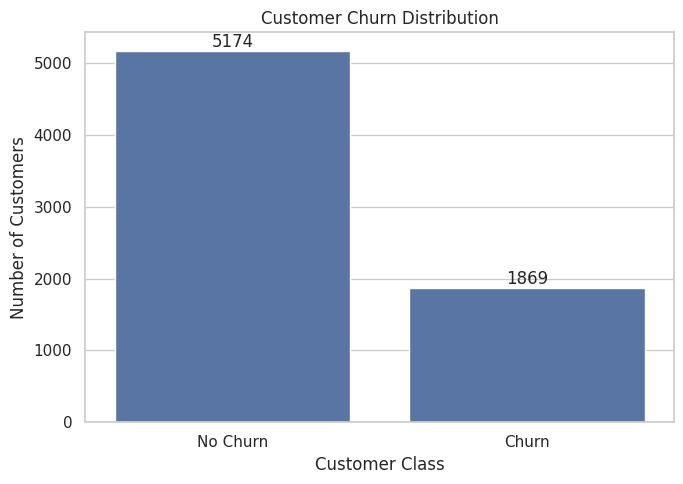


Target distribution:
Churn
No Churn    5174
Churn       1869
Name: count, dtype: int64
Churn percentage: 26.54 %

Data split:
Fitting rows: 4507
Validation rows: 1127
Final test rows: 1409

Training Logistic Regression...

Training Random Forest...

Training Extra Trees...

VALIDATION MODEL COMPARISON
              Model  Threshold  Accuracy  Precision  Recall  F1-score  F2-score  ROC-AUC  PR-AUC
        Extra Trees       0.20    0.6256     0.4102  0.9398    0.5711    0.7469   0.8360  0.6232
Logistic Regression       0.31    0.6513     0.4268  0.9164    0.5824    0.7454   0.8483  0.6668
      Random Forest       0.15    0.6043     0.3975  0.9532    0.5610    0.7449   0.8395  0.6475


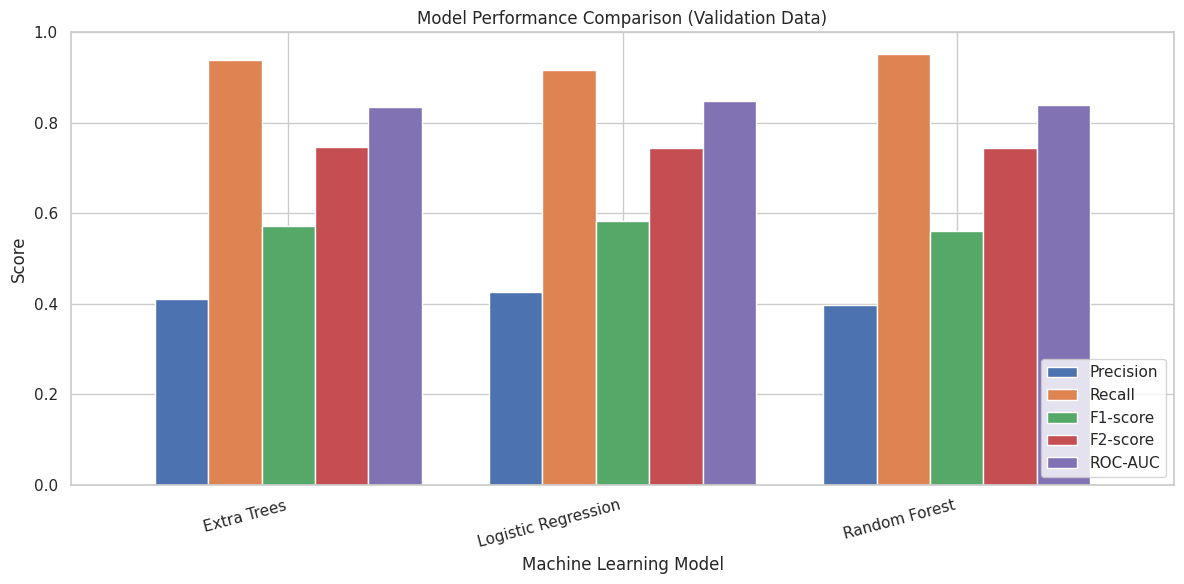

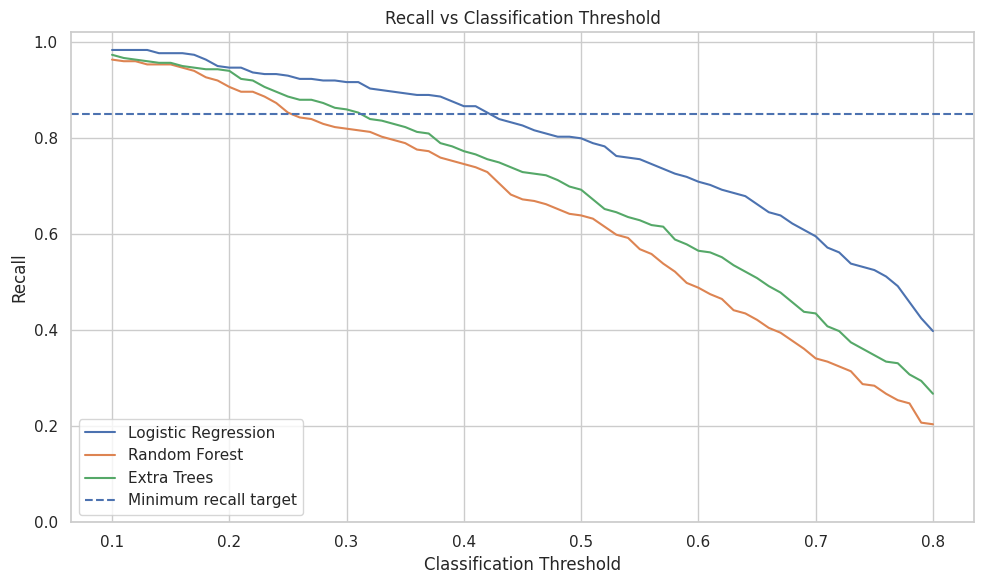


Selected model: Extra Trees
Selected threshold: 0.2

FINAL TEST RESULTS
Selected model: Extra Trees
Threshold: 0.2
Accuracy:  0.6295
Precision: 0.4121
Recall:    0.9278
F1-score:  0.5707
F2-score:  0.7421
ROC-AUC:   0.8319
PR-AUC:    0.6361

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.95      0.52      0.67      1035
       Churn       0.41      0.93      0.57       374

    accuracy                           0.63      1409
   macro avg       0.68      0.72      0.62      1409
weighted avg       0.81      0.63      0.65      1409



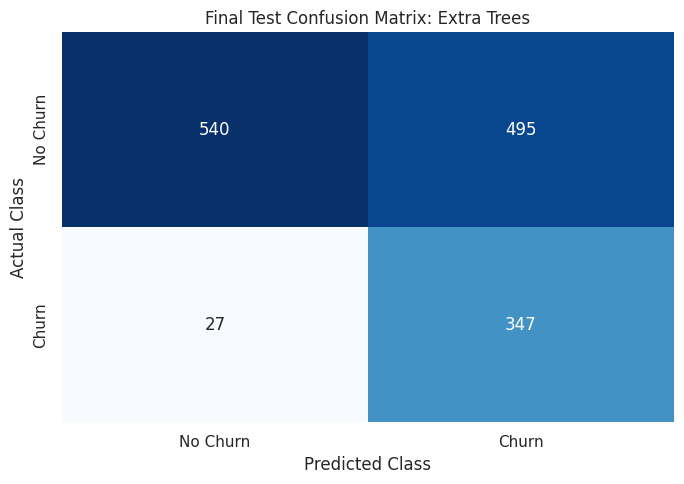

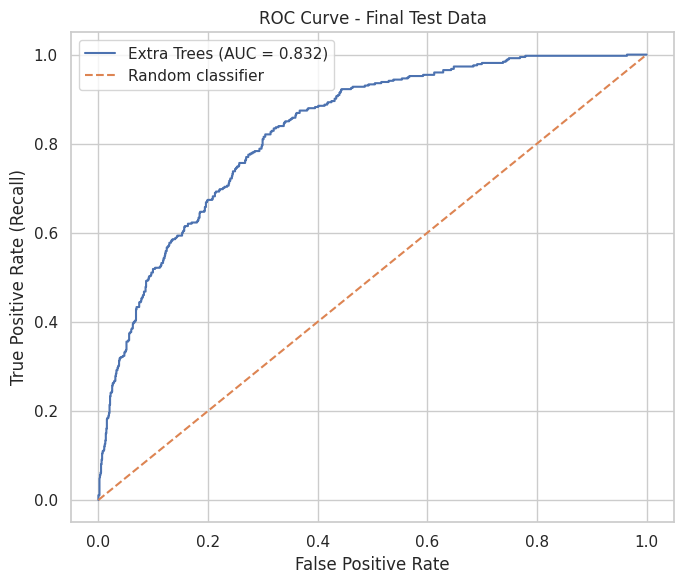

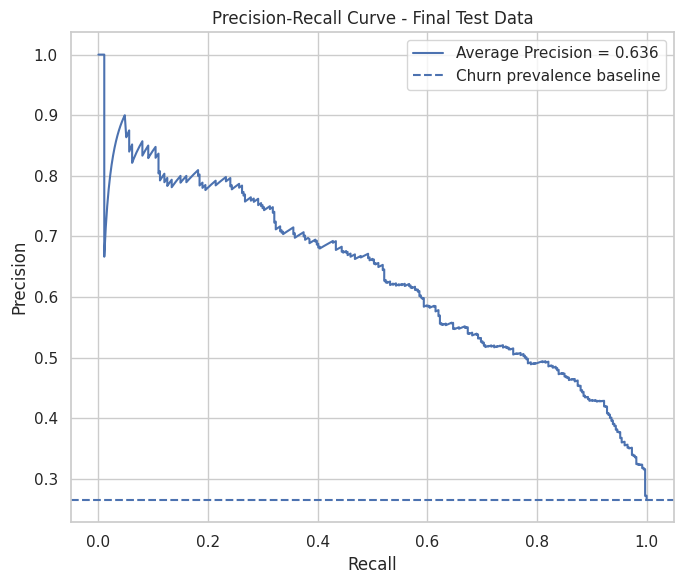

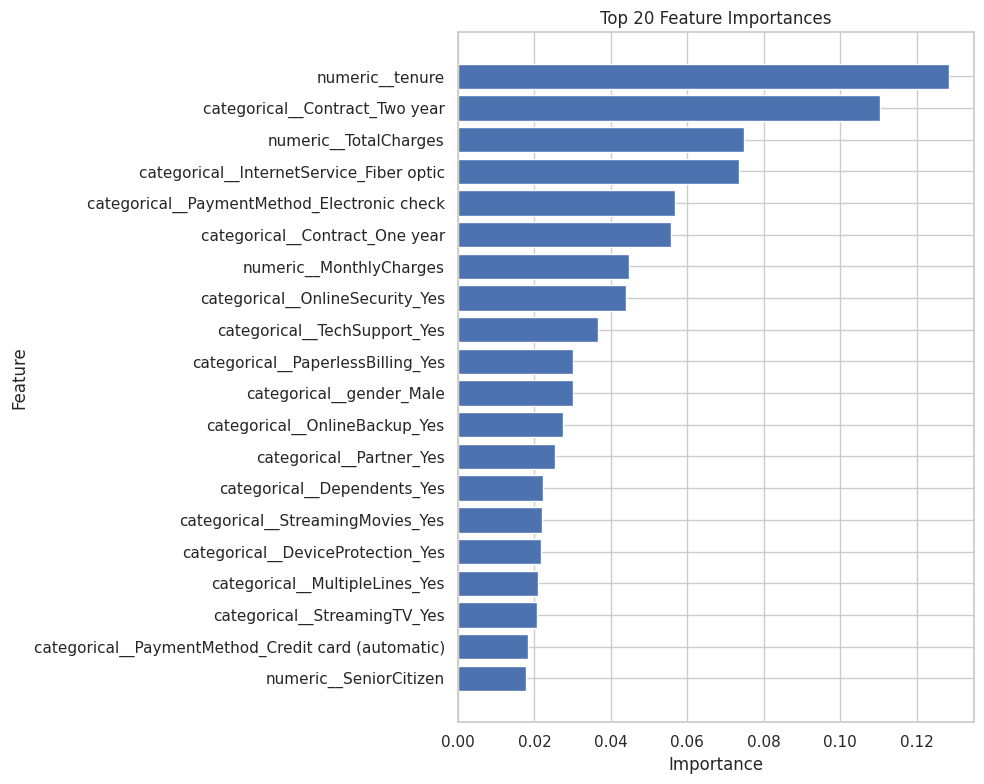


Validation comparison saved successfully.
All visualizations generated.


In [15]:

# ============================================================
# CUSTOMER CHURN PREDICTION
# Model Comparison + Graphical Visualization
# Dataset: Telco Customer Churn
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

RANDOM_STATE = 42
MINIMUM_RECALL = 0.85

sns.set_theme(style="whitegrid")

# ============================================================
# 1. LOAD DATASET
# ============================================================

DATA_PATH = (
    "/kaggle/input/datasets/blastchar/"
    "telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

if not os.path.exists(DATA_PATH):
    # Search the Kaggle input directory if the exact path differs.
    import glob
    matches = glob.glob(
        "/kaggle/input/**/WA_Fn-UseC_-Telco-Customer-Churn.csv",
        recursive=True
    )
    if not matches:
        raise FileNotFoundError(
            "Dataset CSV not found. Check the Kaggle dataset path."
        )
    DATA_PATH = matches[0]

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print(df.head())

# ============================================================
# 2. DATA CLEANING
# ============================================================

# Remove customerID because it is an identifier, not a useful
# predictive feature for generalizing to new customers.
df = df.drop(columns=["customerID"], errors="ignore")

# TotalCharges is often stored as text because some rows contain
# blank strings. Convert it safely to numeric.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"].astype(str).str.strip(),
        errors="coerce"
    )

# Encode target: No = 0, Yes = 1
df["Churn"] = (
    df["Churn"].astype(str).str.strip().str.lower()
    .map({"no": 0, "yes": 1})
)

if df["Churn"].isna().any():
    raise ValueError("Unexpected or missing values found in Churn.")

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# ============================================================
# 3. TARGET DISTRIBUTION VISUALIZATION
# ============================================================

class_counts = df["Churn"].map({
    0: "No Churn",
    1: "Churn"
}).value_counts().reindex(["No Churn", "Churn"])

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)
ax.bar_label(ax.containers[0])
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Class")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\nTarget distribution:")
print(class_counts)
print(
    "Churn percentage:",
    round(df["Churn"].mean() * 100, 2), "%"
)

# ============================================================
# 4. FEATURES AND TARGET
# ============================================================

X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

# First reserve the final test set.
# No model or threshold selection will use this test set.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Create a validation set from training data only.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("\nData split:")
print("Fitting rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Final test rows:", len(X_test))

# ============================================================
# 5. PREPROCESSING
# ============================================================

numeric_cols = X_fit.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_fit.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_cols),
        ("categorical", categorical_transformer, categorical_cols)
    ],
    remainder="drop"
)

# ============================================================
# 6. DEFINE MODELS
# ============================================================

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Extra Trees": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

# ============================================================
# 7. TRAIN MODELS AND SELECT THRESHOLDS ON VALIDATION DATA
# ============================================================

threshold_grid = np.arange(0.10, 0.81, 0.01)

validation_results = []
validation_probabilities = {}
validation_threshold_tables = {}
fitted_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_fit, y_fit)
    fitted_models[name] = model

    probabilities = model.predict_proba(X_val)[:, 1]
    validation_probabilities[name] = probabilities

    threshold_rows = []

    for threshold in threshold_grid:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_rows.append({
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "F2": fbeta_score(
                y_val, predictions, beta=2, zero_division=0
            )
        })

    threshold_df = pd.DataFrame(threshold_rows)
    validation_threshold_tables[name] = threshold_df

    # Prefer thresholds meeting the minimum recall target.
    eligible = threshold_df[
        threshold_df["Recall"] >= MINIMUM_RECALL
    ]

    if eligible.empty:
        # Fallback: highest recall, then highest F2.
        max_recall = threshold_df["Recall"].max()
        eligible = threshold_df[
            threshold_df["Recall"] == max_recall
        ]

    # Within eligible thresholds, maximize F2.
    best = eligible.sort_values(
        ["F2", "Precision"],
        ascending=False
    ).iloc[0]

    best_threshold = float(best["Threshold"])
    val_predictions = (
        probabilities >= best_threshold
    ).astype(int)

    validation_results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "F2-score": fbeta_score(
            y_val, val_predictions, beta=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

validation_table = pd.DataFrame(
    validation_results
).sort_values(
    ["F2-score", "Recall"],
    ascending=False
).reset_index(drop=True)

print("\nVALIDATION MODEL COMPARISON")
print(validation_table.round(4).to_string(index=False))

# ============================================================
# 8. GRAPH 1: MODEL PERFORMANCE COMPARISON
# ============================================================

metric_columns = [
    "Precision", "Recall", "F1-score", "F2-score", "ROC-AUC"
]

plot_data = validation_table.set_index("Model")[
    metric_columns
]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Model Performance Comparison (Validation Data)")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ============================================================
# 9. GRAPH 2: RECALL VS THRESHOLD
# ============================================================

plt.figure(figsize=(10, 6))

for name, probabilities in validation_probabilities.items():

    recalls = [
        recall_score(
            y_val,
            (probabilities >= threshold).astype(int),
            zero_division=0
        )
        for threshold in threshold_grid
    ]

    plt.plot(
        threshold_grid,
        recalls,
        label=name
    )

plt.axhline(
    MINIMUM_RECALL,
    linestyle="--",
    label="Minimum recall target"
)

plt.title("Recall vs Classification Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("Recall")
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 10. SELECT BEST MODEL USING VALIDATION F2
# ============================================================

best_model_name = validation_table.iloc[0]["Model"]
best_threshold = float(
    validation_table.iloc[0]["Threshold"]
)

print("\nSelected model:", best_model_name)
print("Selected threshold:", round(best_threshold, 2))

# Refit the selected model on all training data.
# Test data remains untouched until final evaluation.
final_model = clone(models[best_model_name])
final_model.fit(X_train, y_train)

# ============================================================
# 11. FINAL TEST EVALUATION
# ============================================================

test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nFINAL TEST RESULTS")
print("=" * 50)
print("Selected model:", best_model_name)
print("Threshold:", round(best_threshold, 2))

print(f"Accuracy:  {accuracy_score(y_test, test_predictions):.4f}")
print(f"Precision: {precision_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, test_predictions, zero_division=0):.4f}")
print(f"F2-score:  {fbeta_score(y_test, test_predictions, beta=2, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, test_probabilities):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# ============================================================
# 12. GRAPH 3: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title(f"Final Test Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ============================================================
# 13. GRAPH 4: ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curve - Final Test Data")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 14. GRAPH 5: PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

average_precision = average_precision_score(
    y_test,
    test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Average Precision = {average_precision:.3f}"
)

plt.axhline(
    y_test.mean(),
    linestyle="--",
    label="Churn prevalence baseline"
)

plt.title("Precision-Recall Curve - Final Test Data")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 15. GRAPH 6: FEATURE IMPORTANCE / COEFFICIENTS
# ============================================================

try:
    fitted_preprocessor = final_model.named_steps["preprocessor"]
    fitted_classifier = final_model.named_steps["classifier"]

    feature_names = (
        fitted_preprocessor.get_feature_names_out()
    )

    if hasattr(fitted_classifier, "coef_"):

        coefficients = fitted_classifier.coef_[0]

        feature_table = pd.DataFrame({
            "Feature": feature_names,
            "Value": coefficients
        })

        feature_table["Magnitude"] = (
            feature_table["Value"].abs()
        )

        top_features = feature_table.nlargest(
            20, "Magnitude"
        ).sort_values("Value")

        plt.figure(figsize=(10, 8))

        plt.barh(
            top_features["Feature"],
            top_features["Value"]
        )

        plt.axvline(0, linestyle="--")
        plt.title("Top 20 Logistic Regression Coefficients")
        plt.xlabel("Coefficient (positive = higher churn log-odds)")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

    elif hasattr(fitted_classifier, "feature_importances_"):

        feature_importances = (
            fitted_classifier.feature_importances_
        )

        feature_table = pd.DataFrame({
            "Feature": feature_names,
            "Importance": feature_importances
        }).nlargest(20, "Importance").sort_values("Importance")

        plt.figure(figsize=(10, 8))

        plt.barh(
            feature_table["Feature"],
            feature_table["Importance"]
        )

        plt.title("Top 20 Feature Importances")
        plt.xlabel("Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

except Exception as error:
    print("Feature importance graph unavailable:", error)

# ============================================================
# 16. SAVE VALIDATION RESULTS
# ============================================================

validation_table.to_csv(
    "churn_validation_model_comparison.csv",
    index=False
)

print("\nValidation comparison saved successfully.")
print("All visualizations generated.")


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
files = glob.glob(
    "/kaggle/input/**/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    recursive=True
)

if not files:
    raise FileNotFoundError(
        "Dataset nahi mili. Kaggle ke Add Input option se dataset add karein."
    )

DATA_PATH = files[0]
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [19]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
data = df.copy()

# Remove customer identifier
data.drop(columns=["customerID"], inplace=True, errors="ignore")

# Convert TotalCharges to numeric
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Convert target labels
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

print("Dataset shape after cleaning:", data.shape)
print("\nMissing values after cleaning:")
display(data.isnull().sum()[data.isnull().sum() > 0])

print("\nChurn values:")
print(data["Churn"].value_counts(dropna=False))

Dataset shape after cleaning: (7043, 20)

Missing values after cleaning:


TotalCharges    11
dtype: int64


Churn values:
Churn
0    5174
1    1869
Name: count, dtype: int64


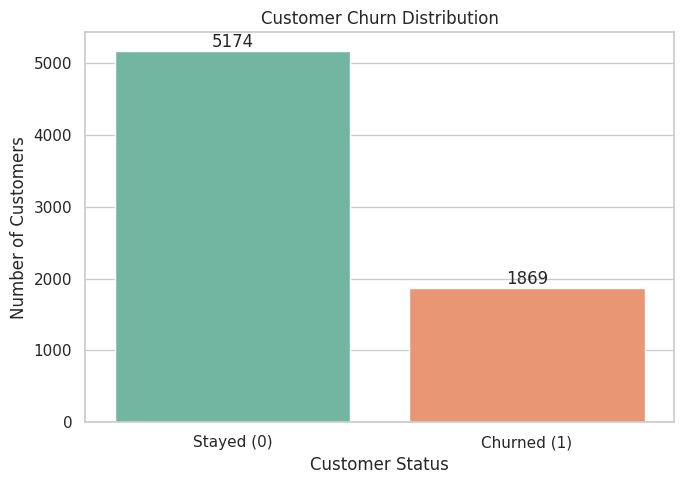

Churn percentage:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

In [21]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=data,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

ax.set_xticks([0, 1], ["Stayed (0)", "Churned (1)"])
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("Churn percentage:")
display((data["Churn"].value_counts(normalize=True) * 100).round(2))

Churn,Stayed (%),Churned (%)
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


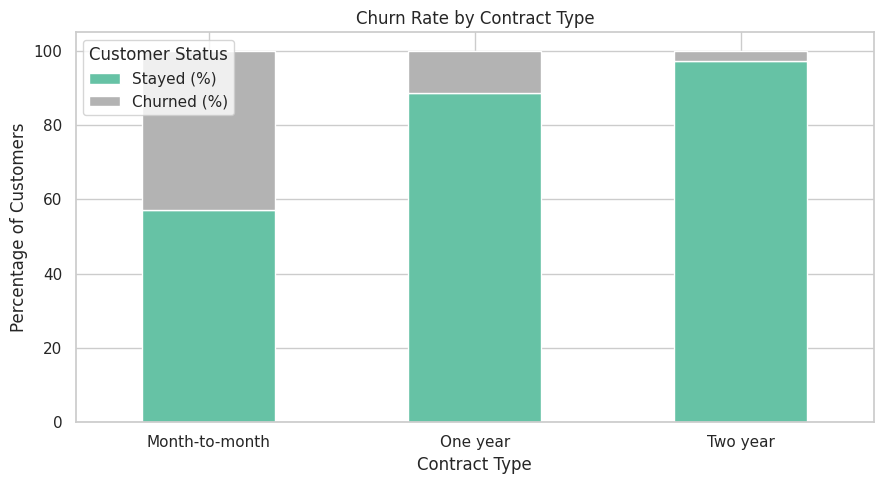

In [22]:
contract_churn = pd.crosstab(
    data["Contract"],
    data["Churn"],
    normalize="index"
) * 100

contract_churn = contract_churn.rename(
    columns={0: "Stayed (%)", 1: "Churned (%)"}
)

display(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Customer Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

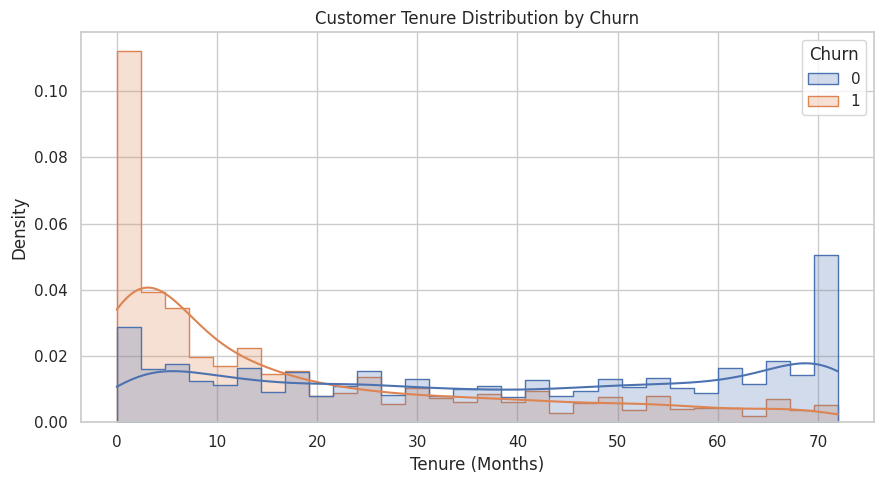

In [23]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

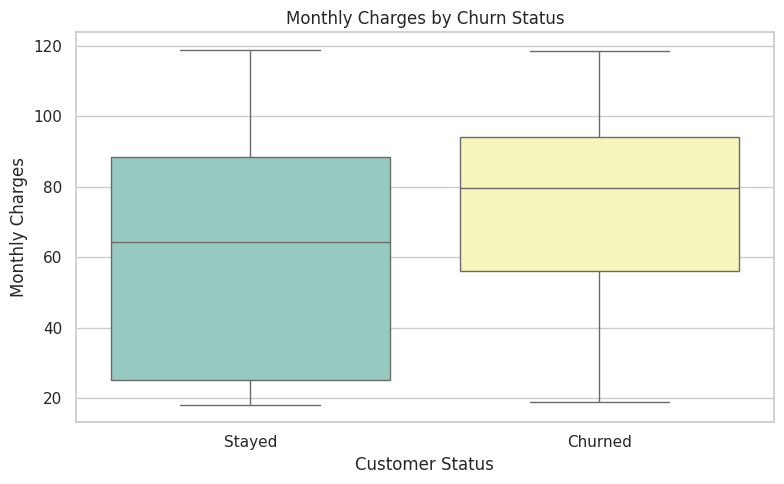

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set3",
    legend=False
)

plt.xticks([0, 1], ["Stayed", "Churned"])
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [25]:
categorical_cols = data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:
    churn_rate = (
        data.groupby(col, dropna=False)["Churn"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {col}:")
    display(churn_rate.round(2))


Churn rate by gender:


gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64


Churn rate by Partner:


Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64


Churn rate by Dependents:


...

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


Churn rate by PaperlessBilling:


PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


Churn rate by PaymentMethod:


PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

In [26]:
# Save the cleaned data for later weeks
data.to_csv("telco_churn_cleaned.csv", index=False)

# Save the EDA summary
eda_summary = pd.DataFrame({
    "Metric": [
        "Total customers",
        "Total features after removing customerID",
        "Missing values",
        "Duplicate rows",
        "Churned customers",
        "Customers who stayed"
    ],
    "Value": [
        len(data),
        data.shape[1],
        int(data.isnull().sum().sum()),
        int(data.duplicated().sum()),
        int((data["Churn"] == 1).sum()),
        int((data["Churn"] == 0).sum())
    ]
})

display(eda_summary)
eda_summary.to_csv("week1_eda_summary.csv", index=False)

print("Week 1 files saved successfully!")

,Metric,Value
0,Total customers,7043
1,Total features after removing customerID,20
2,Missing values,11
3,Duplicate rows,22
4,Churned customers,1869
5,Customers who stayed,5174


Week 1 files saved successfully!


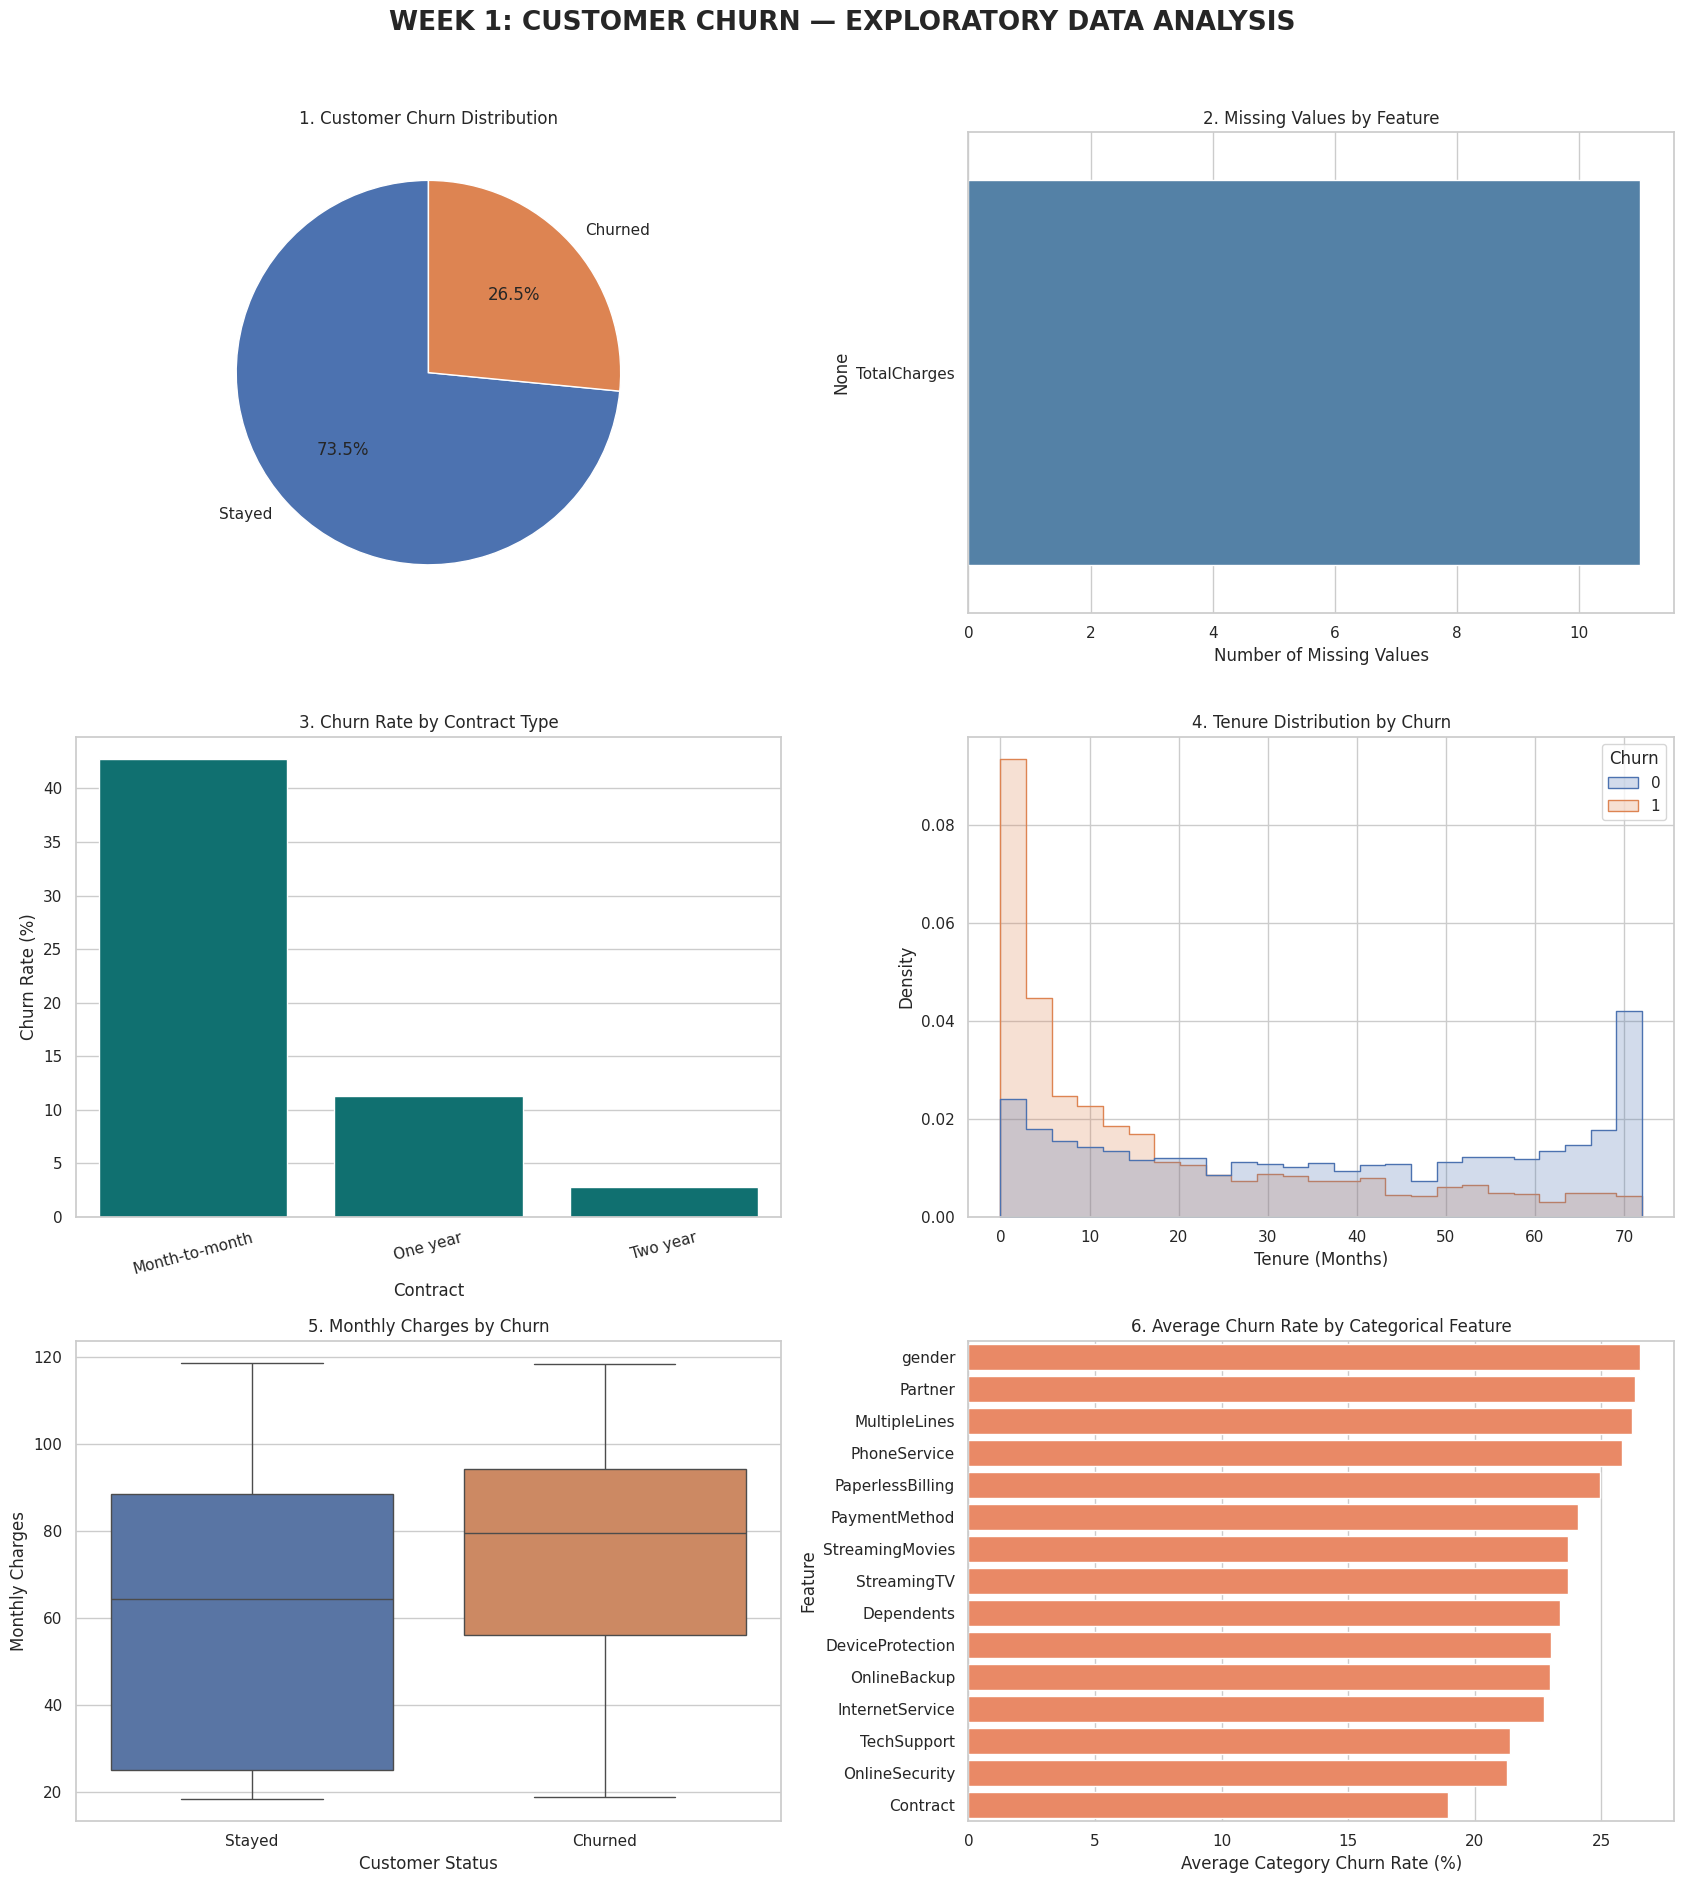

Week 1 EDA dashboard saved successfully!
File: week1_complete_eda_dashboard.png


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Use cleaned dataset created in Week 1
# If data is not available, load the saved CSV
if "data" not in globals():
    data = pd.read_csv("telco_churn_cleaned.csv")

# Create one figure containing all EDA plots
fig, axes = plt.subplots(3, 2, figsize=(17, 19))
fig.suptitle(
    "WEEK 1: CUSTOMER CHURN — EXPLORATORY DATA ANALYSIS",
    fontsize=19,
    fontweight="bold",
    y=0.99
)

# 1. Churn distribution
churn_counts = data["Churn"].map({
    0: "Stayed",
    1: "Churned"
}).value_counts()

axes[0, 0].pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0, 0].set_title("1. Customer Churn Distribution")

# 2. Missing values
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    sns.barplot(
        x=missing.values,
        y=missing.index,
        ax=axes[0, 1],
        color="steelblue"
    )
    axes[0, 1].set_title("2. Missing Values by Feature")
    axes[0, 1].set_xlabel("Number of Missing Values")
else:
    axes[0, 1].text(
        0.5, 0.5, "No missing values",
        ha="center", va="center", fontsize=14
    )
    axes[0, 1].set_title("2. Missing Values")
    axes[0, 1].set_axis_off()

# 3. Contract type vs churn rate
contract_rate = (
    data.groupby("Contract", observed=False)["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=contract_rate.index,
    y=contract_rate.values,
    ax=axes[1, 0],
    color="teal"
)
axes[1, 0].set_title("3. Churn Rate by Contract Type")
axes[1, 0].set_xlabel("Contract")
axes[1, 0].set_ylabel("Churn Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=15)

# 4. Tenure distribution by churn
sns.histplot(
    data=data,
    x="tenure",
    hue="Churn",
    bins=25,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("4. Tenure Distribution by Churn")
axes[1, 1].set_xlabel("Tenure (Months)")
axes[1, 1].set_ylabel("Density")

# 5. Monthly charges by churn
sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    legend=False,
    ax=axes[2, 0]
)
axes[2, 0].set_xticks([0, 1], ["Stayed", "Churned"])
axes[2, 0].set_title("5. Monthly Charges by Churn")
axes[2, 0].set_xlabel("Customer Status")
axes[2, 0].set_ylabel("Monthly Charges")

# 6. Churn rates across categorical features
cat_cols = [
    col for col in data.select_dtypes(include="object").columns
    if data[col].nunique(dropna=False) <= 10
]

if cat_cols:
    rates = pd.DataFrame({
        col: data.groupby(col, dropna=False)["Churn"].mean() * 100
        for col in cat_cols
    })

    # Average category churn rates for each feature
    feature_rates = rates.mean(axis=0).sort_values(ascending=False)

    sns.barplot(
        x=feature_rates.values,
        y=feature_rates.index,
        ax=axes[2, 1],
        color="coral"
    )
    axes[2, 1].set_title("6. Average Churn Rate by Categorical Feature")
    axes[2, 1].set_xlabel("Average Category Churn Rate (%)")
    axes[2, 1].set_ylabel("Feature")
else:
    axes[2, 1].text(
        0.5, 0.5, "No suitable categorical features found",
        ha="center", va="center"
    )
    axes[2, 1].set_axis_off()

plt.tight_layout(rect=[0, 0, 1, 0.97])

# Save the complete dashboard as one image
plt.savefig(
    "week1_complete_eda_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Week 1 EDA dashboard saved successfully!")
print("File: week1_complete_eda_dashboard.png")

****Week 2: Machine Learning Models & Evaluation****

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

sns.set_theme(style="whitegrid")

print("Week 2 libraries imported successfully!")

Week 2 libraries imported successfully!


In [30]:
import os

if "data" not in globals():
    if os.path.exists("telco_churn_cleaned.csv"):
        data = pd.read_csv("telco_churn_cleaned.csv")
    else:
        raise FileNotFoundError(
            "Cleaned dataset nahi mili. Week 1 ka Step 10 run karein "
            "ya cleaned CSV notebook mein upload karein."
        )

# Check the dataset
print("Dataset shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

print("\nChurn distribution:")
print(data["Churn"].value_counts(dropna=False))

display(data.head(10))

Dataset shape: (7043, 20)

Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
5,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
6,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,0
7,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,0
8,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
9,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,0


In [31]:
data = data.copy()

data["Churn"] = pd.to_numeric(data["Churn"], errors="coerce")
data = data.dropna(subset=["Churn"])
data["Churn"] = data["Churn"].astype(int)

X = data.drop(columns=["Churn"])
y = data["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Features: (7043, 19)
Target: (7043,)

Target classes:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data: (5634, 19)
Testing data: (1409, 19)

Training churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [33]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [34]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [35]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [36]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [37]:
extra_trees_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_model.fit(X_train, y_train)

print("Extra Trees training completed!")

Extra Trees training completed!


In [38]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "Extra Trees": extra_trees_model
}

results = []
probabilities = {}

for name, model in models.items():

    # Probability of churn (class 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Default threshold = 0.50
    y_pred = (y_prob >= 0.50).astype(int)

    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "F2 Score": fbeta_score(
            y_test, y_pred, beta=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC
Model,,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.7053,0.8413
Random Forest,0.7807,0.6148,0.4652,0.5297,0.4890,0.8217
Extra Trees,0.7637,0.5643,0.4813,0.5195,0.4959,0.7906


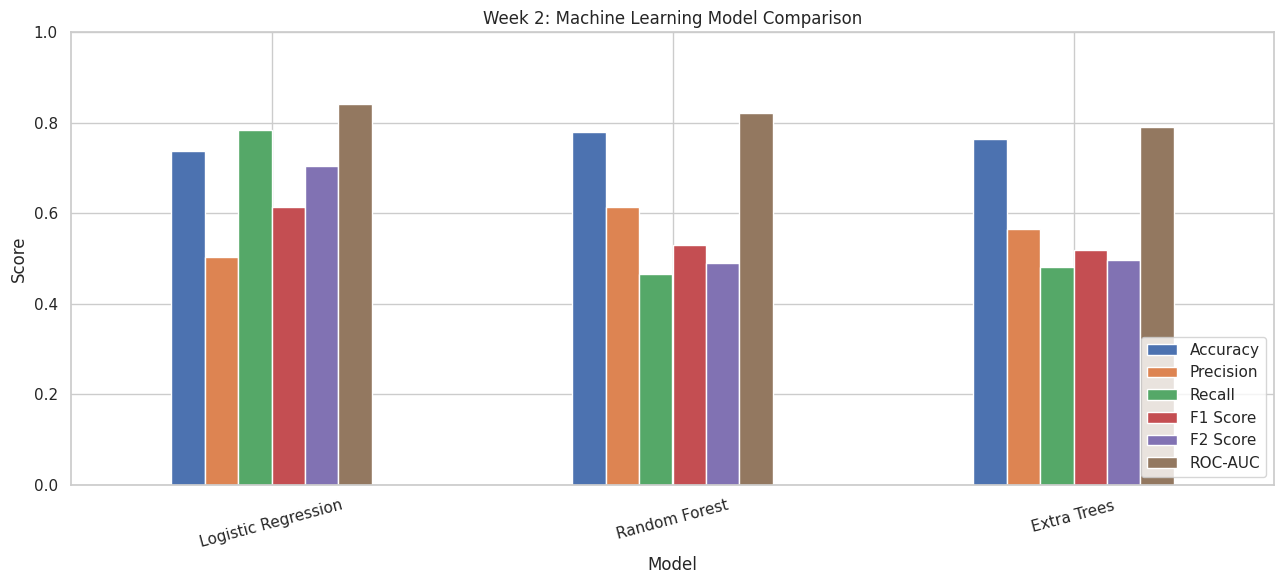

In [39]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "F2 Score",
    "ROC-AUC"
]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Week 2: Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best model by F2-score: Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



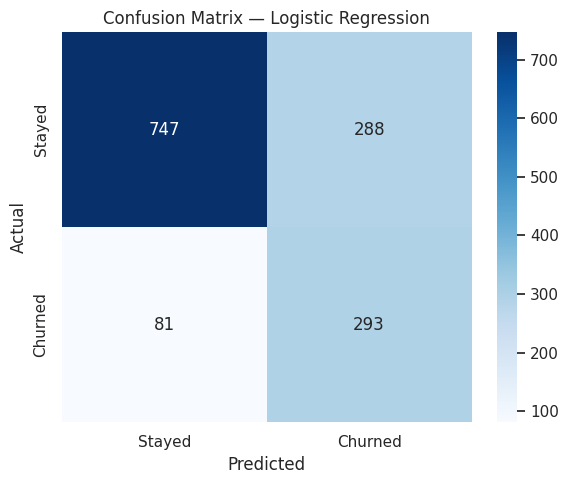

In [40]:
best_model_name = results_df["F2 Score"].idxmax()
best_model = models[best_model_name]

best_prob = probabilities[best_model_name]
best_pred = (best_prob >= 0.50).astype(int)

print("Best model by F2-score:", best_model_name)

print("\nClassification report:")
print(classification_report(
    y_test,
    best_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

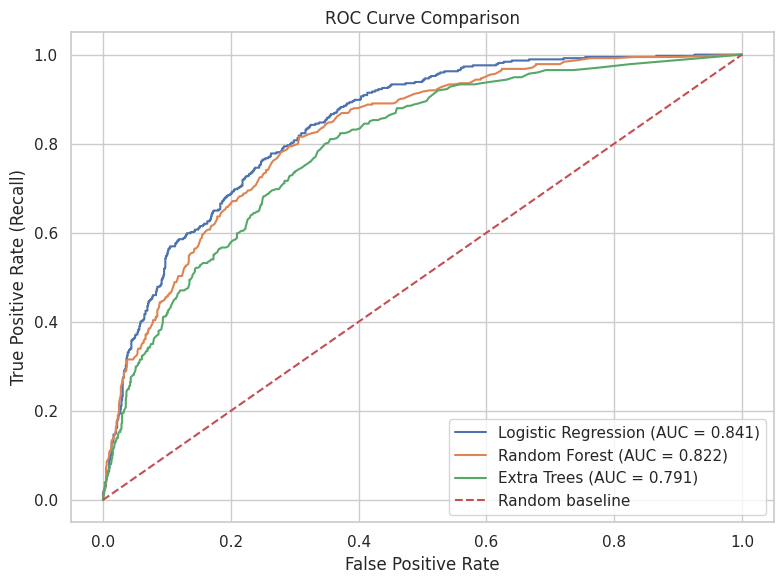

In [41]:
plt.figure(figsize=(8, 6))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.tight_layout()
plt.show()

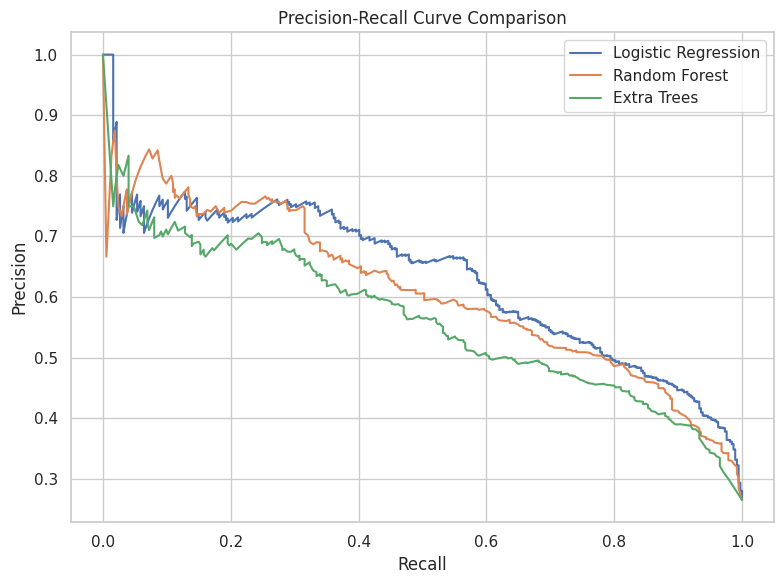

In [42]:
plt.figure(figsize=(8, 6))

for name, y_prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
results_df.to_csv("week2_model_comparison.csv")

# Save actual and predicted probabilities for analysis
predictions_df = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy()
})

for name, y_prob in probabilities.items():
    predictions_df[f"{name}_Churn_Probability"] = y_prob

predictions_df.to_csv(
    "week2_test_predictions.csv",
    index=False
)

print("Week 2 results saved:")
print("- week2_model_comparison.csv")
print("- week2_test_predictions.csv")

Week 2 results saved:
- week2_model_comparison.csv
- week2_test_predictions.csv


****Week 3 — Model Optimization & Unsupervised Learning****

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    silhouette_score,
    precision_recall_curve
)

sns.set_theme(style="whitegrid")
print("Week 3 libraries imported successfully!")

Week 3 libraries imported successfully!


In [46]:
import os
import glob

if "data" not in globals():
    if os.path.exists("telco_churn_cleaned.csv"):
        data = pd.read_csv("telco_churn_cleaned.csv")
    else:
        files = glob.glob(
            "/kaggle/input/**/WA_Fn-UseC_-Telco-Customer-Churn.csv",
            recursive=True
        )
        if not files:
            raise FileNotFoundError(
                "Dataset nahi mili. Week 1 ka cleaned CSV upload karein "
                "ya Kaggle mein dataset add karein."
            )

        data = pd.read_csv(files[0])
        data.drop(columns=["customerID"], errors="ignore", inplace=True)
        data["TotalCharges"] = pd.to_numeric(
            data["TotalCharges"], errors="coerce"
        )
        data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

data = data.copy()
data["Churn"] = pd.to_numeric(data["Churn"], errors="coerce")
data = data.dropna(subset=["Churn"])
data["Churn"] = data["Churn"].astype(int)

print("Dataset shape:", data.shape)
print("\nTarget distribution:")
print(data["Churn"].value_counts())

display(data.head(10))

Dataset shape: (7043, 20)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
5,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
6,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,0
7,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,0
8,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
9,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,0


In [47]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

# First: separate final test set
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: create validation set from remaining 80%
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)

Training: (4225, 19)
Validation: (1409, 19)
Final test: (1409, 19)


In [48]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline ready!")

Numeric features: 4
Categorical features: 15
Preprocessing pipeline ready!


In [50]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, fbeta_score

# Create F2 scoring function
f2_scorer = make_scorer(fbeta_score, beta=2, zero_division=0)

# Create Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
rf_params = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 8, 12, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7]
}

# Randomized search with cross-validation
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=12,
    scoring=f2_scorer,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

# Train and tune the model
rf_search.fit(X_train, y_train)

# Display results
print("Best Random Forest parameters:")
print(rf_search.best_params_)

print(
    "Best cross-validation F2-score:",
    round(rf_search.best_score_, 4)
)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Random Forest parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 8}
Best cross-validation F2-score: 0.707


In [52]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, fbeta_score

# Create F2 scorer
f2_scorer = make_scorer(
    fbeta_score,
    beta=2,
    zero_division=0
)

# Extra Trees pipeline
et_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ExtraTreesClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
et_params = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 8, 12, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7]
}

# Randomized search with valid F2 scoring
et_search = RandomizedSearchCV(
    estimator=et_pipeline,
    param_distributions=et_params,
    n_iter=12,
    scoring=f2_scorer,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

# Train and tune the model
et_search.fit(X_train, y_train)

# Display results
print("Best Extra Trees parameters:")
print(et_search.best_params_)

print(
    "Best cross-validation F2-score:",
    round(et_search.best_score_, 4)
)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Extra Trees parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 8}
Best cross-validation F2-score: 0.714


In [53]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

candidate_models = {
    "Logistic Regression": lr_model,
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned Extra Trees": et_search.best_estimator_
}

validation_results = []

for name, model in candidate_models.items():
    prob = model.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.50).astype(int)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "F2": fbeta_score(y_val, pred, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

validation_df = pd.DataFrame(validation_results).set_index("Model")
display(validation_df.round(4))

,Accuracy,Precision,Recall,F1,F2,ROC-AUC
Model,,,,,,
Logistic Regression,0.7480,0.5166,0.7888,0.6243,0.7136,0.8362
Tuned Random Forest,0.7601,0.5335,0.7674,0.6294,0.7055,0.8377
Tuned Extra Trees,0.7480,0.5169,0.7754,0.6203,0.7049,0.8291


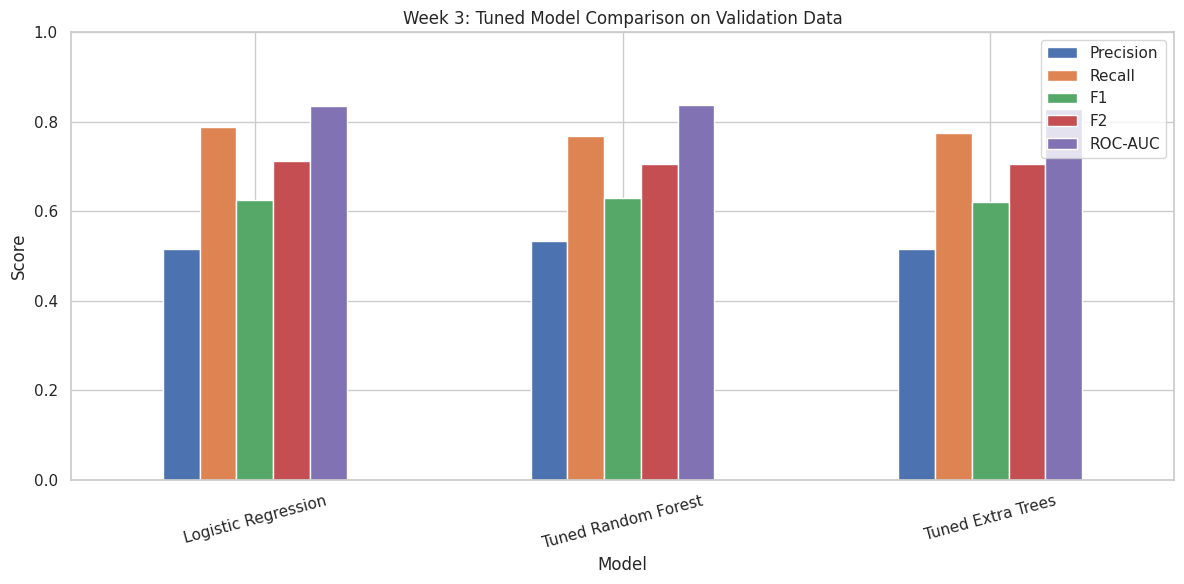

In [54]:
validation_df[["Precision", "Recall", "F1", "F2", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Week 3: Tuned Model Comparison on Validation Data")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [55]:
best_model_name = validation_df["F2"].idxmax()
best_model = candidate_models[best_model_name]

val_prob = best_model.predict_proba(X_val)[:, 1]

threshold_rows = []

for threshold in np.arange(0.10, 0.81, 0.01):
    val_pred = (val_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "F2": fbeta_score(y_val, val_pred, beta=2, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

eligible = threshold_df[threshold_df["Recall"] >= 0.85]

if not eligible.empty:
    best_threshold = float(
        eligible.sort_values(
            ["F2", "Precision"],
            ascending=False
        ).iloc[0]["Threshold"]
    )
else:
    best_threshold = float(
        threshold_df.sort_values(
            ["Recall", "F2"],
            ascending=False
        ).iloc[0]["Threshold"]
    )

print("Selected model:", best_model_name)
print("Selected threshold:", round(best_threshold, 2))

display(threshold_df.sort_values("F2", ascending=False).head(10))

Selected model: Logistic Regression
Selected threshold: 0.3


,Threshold,Precision,Recall,F1,F2
20,0.30,0.419951,0.911765,0.575042,0.738735
21,0.31,0.422167,0.906417,0.576041,0.737277
19,0.29,0.415854,0.911765,0.571189,0.736183
27,0.37,0.443995,0.879679,0.590135,0.735360
29,0.39,0.453278,0.868984,0.595784,0.734297
18,0.28,0.409581,0.914439,0.565757,0.733591
28,0.38,0.446575,0.871658,0.590580,0.732255
24,0.34,0.430052,0.887701,0.579407,0.731922
23,0.33,0.426923,0.890374,0.577123,0.731547
17,0.27,0.403055,0.917112,0.560000,0.730720


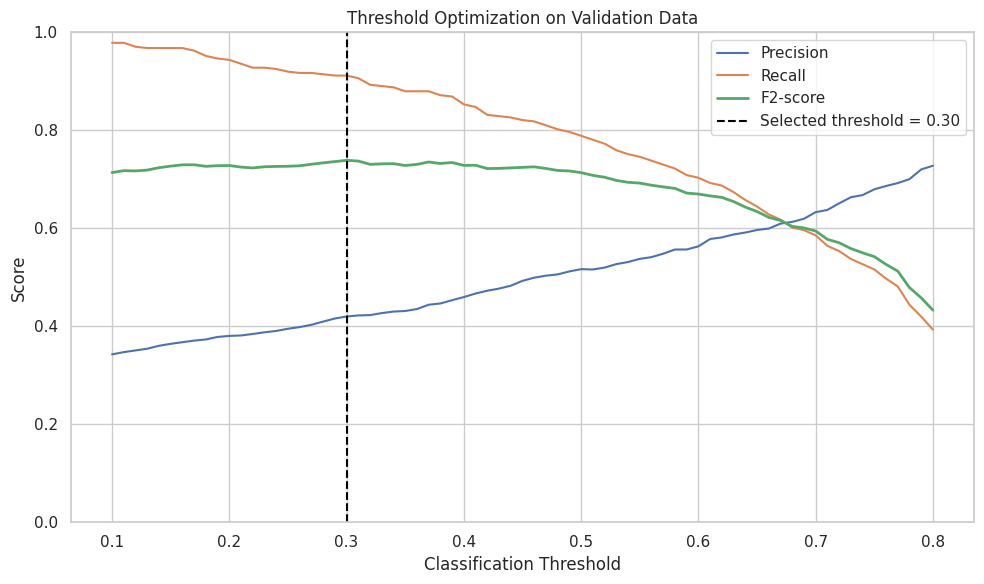

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["F2"],
    label="F2-score",
    linewidth=2
)

plt.axvline(
    best_threshold,
    color="black",
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.title("Threshold Optimization on Validation Data")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [57]:
cluster_features = [
    col for col in ["tenure", "MonthlyCharges", "TotalCharges"]
    if col in X_train.columns
]

if len(cluster_features) < 2:
    raise ValueError(
        "Clustering ke liye kam az kam 2 numerical features zaroori hain."
    )

cluster_data = data[cluster_features].copy()

cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(
    cluster_imputer.fit_transform(cluster_data)
)

print("Clustering features:", cluster_features)
print("Scaled clustering data:", cluster_scaled.shape)

Clustering features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Scaled clustering data: (7043, 3)


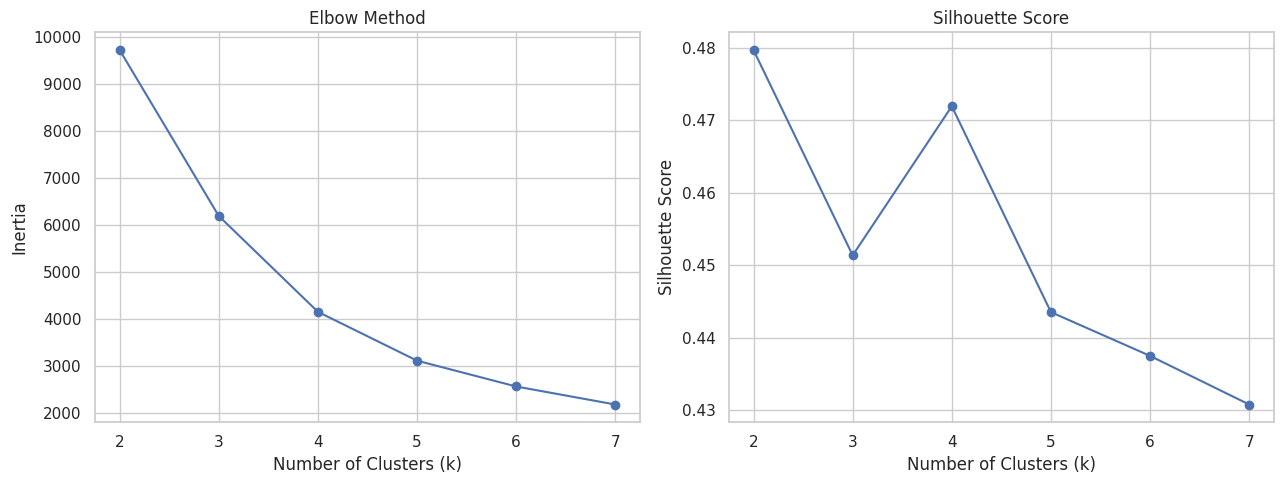

Silhouette scores:
k=2: 0.4797
k=3: 0.4514
k=4: 0.4720
k=5: 0.4435
k=6: 0.4375
k=7: 0.4307


In [58]:
inertias = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = km.fit_predict(cluster_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(
        silhouette_score(cluster_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.4f}")

In [59]:
chosen_k = 3

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

data["CustomerSegment"] = kmeans.fit_predict(cluster_scaled)

print("Customer segment sizes:")
display(data["CustomerSegment"].value_counts().sort_index())

print("\nSegment profiles:")
display(
    data.groupby("CustomerSegment")[
        cluster_features + ["Churn"]
    ].mean().round(2)
)

Customer segment sizes:


CustomerSegment
0    2154
1    2200
2    2689
Name: count, dtype: int64


Segment profiles:


,tenure,MonthlyCharges,TotalCharges,Churn
CustomerSegment,,,,
0,29.50,26.57,811.68,0.12
1,58.56,89.70,5246.13,0.15
2,13.25,74.95,1032.49,0.47


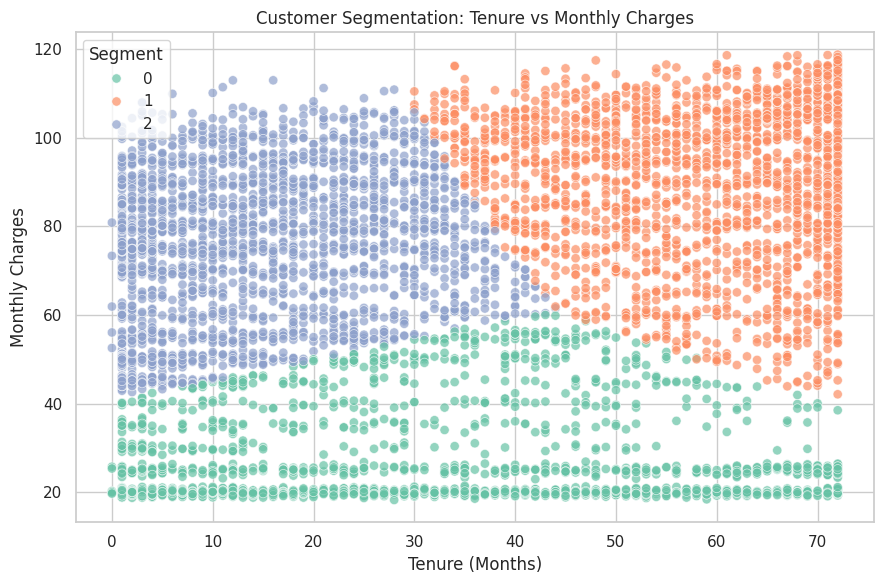

In [60]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=data,
    x="tenure",
    y="MonthlyCharges",
    hue="CustomerSegment",
    palette="Set2",
    alpha=0.7,
    s=45
)

plt.title("Customer Segmentation: Tenure vs Monthly Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Segment")
plt.tight_layout()
plt.show()

Final selected model: Logistic Regression
Selected threshold: 0.3

Final test classification report:
              precision    recall  f1-score   support

      Stayed       0.96      0.56      0.71      1035
     Churned       0.43      0.93      0.59       374

    accuracy                           0.66      1409
   macro avg       0.70      0.75      0.65      1409
weighted avg       0.82      0.66      0.68      1409



,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC
0,Logistic Regression,0.3,0.66,0.4346,0.9332,0.593,0.759,0.8426


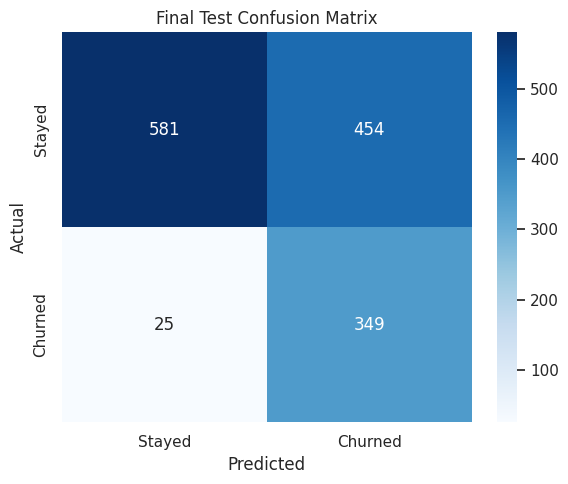

In [61]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("Final selected model:", best_model_name)
print("Selected threshold:", round(best_threshold, 2))

print("\nFinal test classification report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

final_metrics = {
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "F2": fbeta_score(y_test, test_pred, beta=2, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}

display(pd.DataFrame([final_metrics]).round(4))

cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [62]:
validation_df.to_csv("week3_validation_model_comparison.csv")
threshold_df.to_csv("week3_threshold_analysis.csv", index=False)
pd.DataFrame([final_metrics]).to_csv(
    "week3_final_test_metrics.csv",
    index=False
)

data.to_csv("week3_customer_segments.csv", index=False)

print("Week 3 outputs saved:")
print("- week3_validation_model_comparison.csv")
print("- week3_threshold_analysis.csv")
print("- week3_final_test_metrics.csv")
print("- week3_customer_segments.csv")

Week 3 outputs saved:
- week3_validation_model_comparison.csv
- week3_threshold_analysis.csv
- week3_final_test_metrics.csv
- week3_customer_segments.csv


Week 4: Streamlit Application

In [63]:
import joblib
import os

# Create output directory
os.makedirs("/kaggle/working", exist_ok=True)

# Use the optimized threshold from Week 3
if "best_threshold" not in globals():
    best_threshold = 0.50

# Save model and its required information
model_artifacts = {
    "model": best_model,
    "threshold": best_threshold,
    "feature_columns": list(X_train.columns)
}

joblib.dump(
    model_artifacts,
    "/kaggle/working/churn_model.pkl"
)

print("Model saved successfully!")
print("File: /kaggle/working/churn_model.pkl")
print("Threshold:", best_threshold)
print("Number of input features:", len(X_train.columns))

Model saved successfully!
File: /kaggle/working/churn_model.pkl
Threshold: 0.3
Number of input features: 19


In [64]:
pip install streamlit pandas numpy scikit-learn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 76.6 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 89.0 MB/s eta 0:00:00:00:010:01
Note: you may need to restart the kernel to use updated packages.


In [67]:

import streamlit as st
import pandas as pd
import joblib
import os

# -----------------------------
# 1. Page configuration
# -----------------------------
st.set_page_config(
    page_title="/kaggle/working/.virtual_documents/__notebook_source__.ipynb",
    page_icon="📊",
    layout="wide"
)

# -----------------------------
# 2. Load trained model
# -----------------------------
MODEL_PATH = os.path.join(
    os.path.dirname(__file__),
    "churn_model.pkl"
)

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

try:
    artifacts = load_model()
    model = artifacts["model"]
    threshold = artifacts["threshold"]
    feature_columns = artifacts["feature_columns"]
except Exception as e:
    st.error(f"Unable to load model: {e}")
    st.stop()

# -----------------------------
# 3. Application heading
# -----------------------------
st.title("📊 Churn Risk Advisor")
st.subheader("Customer Churn Prediction System")

st.write(
    "Enter customer details below to estimate the probability "
    "that the customer will leave the service."
)

st.info(
    f"Prediction threshold selected in Week 3: {threshold:.2f}"
)

# -----------------------------
# 4. Customer input form
# -----------------------------
with st.form("customer_form"):

    st.header("Customer Information")

    col1, col2, col3 = st.columns(3)

    with col1:
        gender = st.selectbox(
            "Gender", ["Female", "Male"]
        )

        senior_citizen = st.selectbox(
            "Senior Citizen", [0, 1],
            format_func=lambda x: "Yes" if x == 1 else "No"
        )

        partner = st.selectbox(
            "Has Partner?", ["Yes", "No"]
        )

        dependents = st.selectbox(
            "Has Dependents?", ["Yes", "No"]
        )

        tenure = st.number_input(
            "Tenure (months)",
            min_value=0,
            max_value=100,
            value=12
        )

        phone_service = st.selectbox(
            "Phone Service", ["Yes", "No"]
        )

    with col2:
        multiple_lines = st.selectbox(
            "Multiple Lines",
            ["No", "Yes", "No phone service"]
        )

        internet_service = st.selectbox(
            "Internet Service",
            ["DSL", "Fiber optic", "No"]
        )

        online_security = st.selectbox(
            "Online Security",
            ["Yes", "No", "No internet service"]
        )

        online_backup = st.selectbox(
            "Online Backup",
            ["Yes", "No", "No internet service"]
        )

        device_protection = st.selectbox(
            "Device Protection",
            ["Yes", "No", "No internet service"]
        )

        tech_support = st.selectbox(
            "Tech Support",
            ["Yes", "No", "No internet service"]
        )

    with col3:
        streaming_tv = st.selectbox(
            "Streaming TV",
            ["Yes", "No", "No internet service"]
        )

        streaming_movies = st.selectbox(
            "Streaming Movies",
            ["Yes", "No", "No internet service"]
        )

        contract = st.selectbox(
            "Contract",
            ["Month-to-month", "One year", "Two year"]
        )

        paperless_billing = st.selectbox(
            "Paperless Billing", ["Yes", "No"]
        )

        payment_method = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )

        monthly_charges = st.number_input(
            "Monthly Charges",
            min_value=0.0,
            value=70.0,
            step=1.0
        )

        total_charges = st.number_input(
            "Total Charges",
            min_value=0.0,
            value=840.0,
            step=10.0
        )

    submitted = st.form_submit_button(
        "Predict Churn Risk",
        use_container_width=True
    )

# -----------------------------
# 5. Make prediction
# -----------------------------
if submitted:

    customer_data = {
        "gender": gender,
        "SeniorCitizen": senior_citizen,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges
    }

    # Match the exact training feature names and order
    input_df = pd.DataFrame([customer_data])
    input_df = input_df.reindex(columns=feature_columns)

    # Predict probability for Churn = 1
    probabilities = model.predict_proba(input_df)[0]
    classes = list(model.classes_)
    churn_index = classes.index(1)
    churn_probability = probabilities[churn_index]

    # Apply the threshold selected in Week 3
    prediction = int(churn_probability >= threshold)

    st.divider()
    st.header("Prediction Results")

    result_col1, result_col2 = st.columns(2)

    with result_col1:
        st.metric(
            "Churn Probability",
            f"{churn_probability:.1%}"
        )

        st.progress(float(churn_probability))

    with result_col2:
        if prediction == 1:
            st.error("⚠️ Prediction: Customer is at risk of churning")
        else:
            st.success("✅ Prediction: Customer is not flagged for churn")

    # Risk category for easier interpretation
    if churn_probability >= 0.60:
        risk_level = "High"
        st.warning("High-risk customer: consider proactive retention.")
    elif churn_probability >= 0.30:
        risk_level = "Medium"
        st.info("Medium-risk customer: monitor engagement.")
    else:
        risk_level = "Low"
        st.success("Low-risk customer: maintain service quality.")

    st.subheader("Recommended Action")

    if risk_level == "High":
        st.write(
            "- Contact the customer to understand concerns.\n"
            "- Review contract and pricing options.\n"
            "- Offer suitable support or retention incentives."
        )
    elif risk_level == "Medium":
        st.write(
            "- Monitor customer satisfaction.\n"
            "- Explain available plans and support options.\n"
            "- Review service usage and engagement."
        )
    else:
        st.write(
            "- Continue providing reliable service.\n"
            "- Maintain customer communication.\n"
            "- Review risk again when new data becomes available."
        )

    st.caption(
        "This is a machine-learning estimate, not a guarantee "
        "of future customer behavior. Risk bands are illustrative."
    )


2026-10-18 10:04:11.020 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NameError: name '__file__' is not defined

In [68]:
import streamlit as st
import pandas as pd
import joblib
import os

MODEL_PATH = "/kaggle/working/churn_model.pkl"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

artifacts = load_model()

model = artifacts["model"]
threshold = artifacts["threshold"]
feature_columns = artifacts["feature_columns"]

print("Model loaded successfully!")
print("Threshold:", threshold)
print("Features:", len(feature_columns))

2026-10-18 10:05:48.029 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Model loaded successfully!
Threshold: 0.3
Features: 19


In [69]:
import os

print("Files in /kaggle/working:")
print(os.listdir("/kaggle/working"))

model_path = "/kaggle/working/churn_model.pkl"

if os.path.exists(model_path):
    print("Model file found!")
else:
    print("Model file not found. Save the Week 3 model first.")

Files in /kaggle/working:
['week3_threshold_analysis.csv', 'week2_test_predictions.csv', 'week3_customer_segments.csv', 'churn_validation_model_comparison.csv', 'week2_model_comparison.csv', '.virtual_documents', 'churn_model.pkl', 'week3_final_test_metrics.csv', 'week1_eda_summary.csv', 'week1_complete_eda_dashboard.png', 'week3_validation_model_comparison.csv', 'telco_churn_cleaned.csv']
Model file found!


In [70]:
import joblib

model_path = "/kaggle/working/churn_model.pkl"

artifacts = joblib.load(model_path)

model = artifacts["model"]
threshold = artifacts["threshold"]
feature_columns = artifacts["feature_columns"]

print("Model loaded successfully!")
print("Threshold:", threshold)
print("Number of features:", len(feature_columns))
print("Feature names:", feature_columns)

Model loaded successfully!
Threshold: 0.3
Number of features: 19
Feature names: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [71]:
import pandas as pd

# Use one customer record from the test dataset
sample = X_test.iloc[[0]].copy()

probabilities = model.predict_proba(sample)[0]
classes = list(model.classes_)

churn_index = classes.index(1)
churn_probability = probabilities[churn_index]

prediction = int(churn_probability >= threshold)

print("Churn Probability:", round(churn_probability * 100, 2), "%")
print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Threshold:", threshold)

Churn Probability: 10.62 %
Prediction: No Churn
Threshold: 0.3
